# 문서 탐색(EDA) — 바이오·헬스케어 제공 뉴스 데이터

**주제 B. 산업·기술 동향** / 선택 산업: **바이오·헬스케어**

이 노트북은 제공받은 뉴스 CSV 3종을 탐색해 ① 수집기(`collector/load_provided.py`)의 **선별 규칙**과
② 인덱서의 **청킹·중복 처리 설계**에 필요한 근거를 정리한다.

| 파일 | 수집 키워드 | 행 수 |
|---|---|---|
| `04_바이오헬스_키워드_바이오의약품_6580건_…csv` | 바이오 의약품 | 6,580 |
| `04_바이오헬스_키워드_디지털헬스케어_25991건_…csv` | 디지털 헬스케어 | 25,991 |
| `04_바이오헬스_묶음_바이오헬스케어_32454건_…csv` | 두 키워드 묶음 | 32,454 |

수집 기간: 2021-10-16 ~ 2026-10-16 (5년), 원본 위치: `data/provided/`

**탐색 질문**
1. 세 파일은 서로 어떤 관계인가? (중복 범위)
2. 시간·매체·키워드 분포는 균형적인가? (시간축 근거로 쓸 수 있는가)
3. 본문 품질 — 빈 본문, 사진기사, 보일러플레이트, 중복은 얼마나 되는가?
4. 과제 키워드표의 하위 주제(ADC·CDMO·AI 신약개발·바이오 투자·신약 기술수출·의료 AI 규제)는 얼마나 커버되는가?
5. 뉴스 안에 '전망' 서술이 얼마나 있는가? (투자보고서와 상충 비교의 후보)

In [1]:
import sys, re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from collector import load_provided as lp  # 선별 로직을 그대로 재사용

plt.rcParams["font.family"] = "Malgun Gothic"   # Windows 한글 폰트 (macOS: AppleGothic)
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 80)

DATA_DIR = PROJECT_ROOT / "data" / "provided"
files = lp.discover_files(DATA_DIR)
def short_name(p):  # 04_바이오헬스_{묶음|키워드}_{이름}_… → 묶음 / 디지털헬스케어 / 바이오의약품
    parts = lp.nfc(p.name).split("_")
    return "묶음" if parts[2] == "묶음" else parts[3]

raw = {short_name(p): lp.read_provided(p) for p in files}
{k: v.shape for k, v in raw.items()}

{'묶음': (32454, 8), '디지털헬스케어': (25991, 8), '바이오의약품': (6580, 8)}

## 1. 스키마와 결측

In [2]:
bundle = raw["묶음"]
print(bundle.dtypes.to_string())
bundle.head(3)

title               str
body                str
url                 str
published_at        str
press               str
doc_type            str
collect_keywords    str
source_file         str


,title,body,url,published_at,press,doc_type,collect_keywords,source_file
0,충북에 국내 유일 바이오 의약품 소재·부품·장비 실증센터,바이오 의약품의 성능을 평가하고 안전성을 검증해 국제 규격화하는 국내 유일의 '바이오 의약품 소재 부품 실증 지원 테스트 베드'(시험장)...,https://n.news.naver.com/mnews/article/028/0002715151,2024-11-07T16:08:00,한겨레,news,바이오 의약품,04_바이오헬스_묶음_바이오헬스케어_32454건_2021-10-16~2026-10-16.csv
1,"인하대, GMP 교육 참여 교육생 모집…기업 방문 현장맞춤형 교육 진행",인하대학교(총장 조명우)가 바이오 의약품 원부자재 관련 GMP(Good Manufacturing Practice) 교육이 필요한 기업의 ...,https://n.news.naver.com/mnews/article/076/0003908287?sid=102,2022-08-24T09:58:00,스포츠조선,news,바이오 의약품,04_바이오헬스_묶음_바이오헬스케어_32454건_2021-10-16~2026-10-16.csv
2,日 바이오 의약품 해외 의존도 높아…코로나 백신에 '2조원' 투자,"일본 바이오 의약품 시장 규모가 95조원에 달하며 매년 커져가고 있지만, 해외 수입 의존도가 많게는 90% 가까이 되는 것으로 조사됐다....",https://n.news.naver.com/mnews/article/421/0007162190?sid=101,2023-11-08T14:17:00,뉴스1,news,바이오 의약품,04_바이오헬스_묶음_바이오헬스케어_32454건_2021-10-16~2026-10-16.csv


In [3]:
pd.DataFrame({k: (v == "").sum() for k, v in raw.items()}).T

,title,body,url,published_at,press,doc_type,collect_keywords,source_file
묶음,0,16,0,0,0,0,0,0
디지털헬스케어,0,16,0,0,0,0,0,0
바이오의약품,0,0,0,0,0,0,0,0


- 7개 컬럼(`제목, 본문전문, 원문URL, 발행일, 매체명, 문서종류, 수집키워드`) 공통, **문서종류는 전부 `news`**.
- 결측은 본문 16건뿐 → 스키마는 깨끗하다. 특허·보고서는 별도 크롤링(`crawl_korea_kr.py` 등)으로 보강해야 한다.

## 2. 파일 간 관계 — 묶음 파일은 키워드 파일의 합집합인가?

In [4]:
ids = {k: set(v["url"].map(lp.make_doc_id)) for k, v in raw.items()}
dh, bio, bun = ids["디지털헬스케어"], ids["바이오의약품"], ids["묶음"]
pd.Series({
    "디지털헬스케어": len(dh), "바이오의약품": len(bio), "묶음": len(bun),
    "디지털 ∩ 바이오": len(dh & bio),
    "디지털 ∪ 바이오": len(dh | bio),
    "묶음 - (디지털 ∪ 바이오)": len(bun - (dh | bio)),
    "(디지털 ∪ 바이오) - 묶음": len((dh | bio) - bun),
})

디지털헬스케어             25989
바이오의약품               6580
묶음                  32452
디지털 ∩ 바이오             117
디지털 ∪ 바이오           32452
묶음 - (디지털 ∪ 바이오)        0
(디지털 ∪ 바이오) - 묶음        0
dtype: int64

- **묶음 파일 = 두 키워드 파일의 합집합**(겹침 117건은 `수집키워드 = "디지털 헬스케어; 바이오 의약품"`으로 표시).
- 세 파일을 그냥 합치면 65,025행이지만 **고유 문서는 32,452건** → 적재 시 반드시 문서 ID 기준 병합이 필요하다.
- 네이버 뉴스 URL은 형식이 여러 가지(`/mnews/article/…`, `read.naver?oid=…&aid=…` 등)라 URL 문자열이 아니라 **언론사ID(oid)+기사ID(aid)** 로 ID를 만든다(`make_doc_id`).

In [5]:
u = bundle["url"].str.replace(r"\d+", "N", regex=True)
u.value_counts().head(8)

url
https://n.news.naver.com/mnews/article/N/N                                            16835
https://n.news.naver.com/mnews/article/N/N?sid=N                                      13152
https://news.naver.com/main/read.naver?mode=LSND&mid=shm&sidN=N&sidN=N&oid=N&aid=N     1194
https://n.news.naver.com/article/N/N                                                   1192
https://m.entertain.naver.com/article/N/N                                                26
https://sports.news.naver.com/news?oid=N&aid=N                                           18
https://sports.news.naver.com/news.nhn?oid=N&aid=N                                        9
https://entertain.naver.com/now/read?oid=N&aid=N                                          7
Name: count, dtype: int64

## 3. 키워드 불균형

collect_keywords
디지털 헬스케어             25874
바이오 의약품               6463
디지털 헬스케어; 바이오 의약품      117
Name: count, dtype: int64

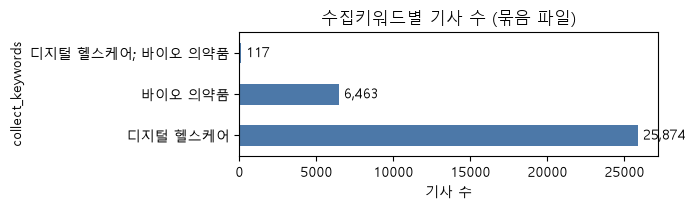

In [6]:
kw = bundle["collect_keywords"].value_counts()
ax = kw.plot.barh(figsize=(7, 2.2), color="#4C78A8")
ax.set_xlabel("기사 수"); ax.set_title("수집키워드별 기사 수 (묶음 파일)")
for i, v in enumerate(kw): ax.text(v, i, f" {v:,}", va="center")
plt.tight_layout(); kw

- 디지털 헬스케어 : 바이오 의약품 ≈ **4 : 1**. 바이오 의약품 질문이 디지털 헬스케어 문서에 묻히지 않도록
  메타데이터 필터(`collect_keywords`, `topics`)를 제공해야 한다.

## 4. 시간 분포 — 시간축 근거로 쓸 수 있는가

kw,디지털 헬스케어,바이오 의약품
published_at,,
2025Q3,1888,399
2025Q4,1863,355
2026Q1,1829,238
2026Q2,1362,273
2026Q3,1339,257
2026Q4,148,22


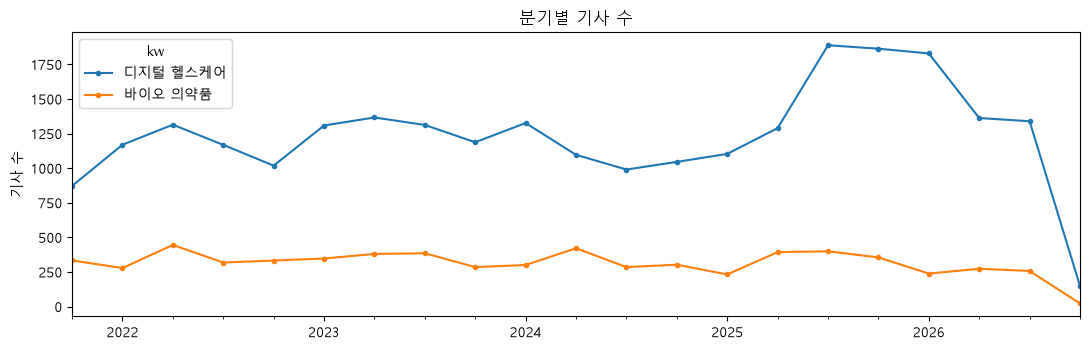

In [7]:
b = bundle.assign(published_at=pd.to_datetime(bundle["published_at"]))
ex = b.assign(kw=b["collect_keywords"].str.split("; ")).explode("kw")
q = ex.groupby([ex["published_at"].dt.to_period("Q"), "kw"]).size().unstack(fill_value=0)
ax = q.plot(figsize=(11, 3.6), marker="o", ms=3)
ax.set_title("분기별 기사 수"); ax.set_xlabel(""); ax.set_ylabel("기사 수")
plt.tight_layout(); q.tail(6)

- 5년 전 구간에 분기당 1,200~2,300건으로 **공백 없이 분포** → '현재(뉴스)' 시간축 근거로 충분하다.
- 2025Q3~2026Q1에 기사량이 증가했고, **2026Q4는 10월 16일까지만 수집**되어 낮게 보인다(추이 해석 시 주의).

## 5. 매체 분포

매체 수: 106 / 상위 10개 비중: 0.517


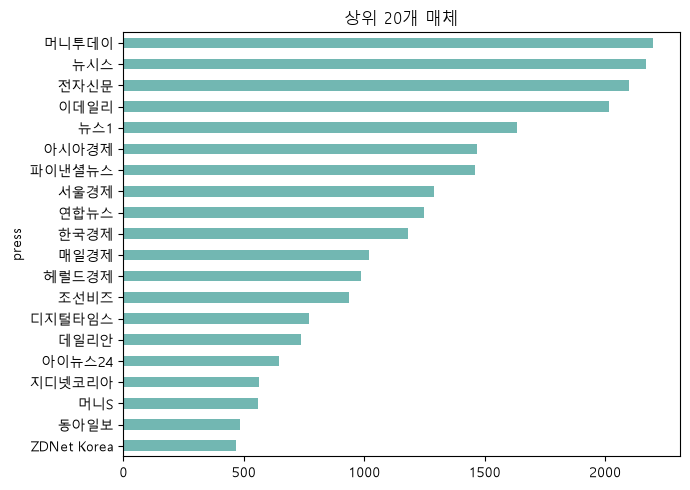

In [8]:
press = bundle["press"].value_counts()
print("매체 수:", press.size, "/ 상위 10개 비중:", round(press.head(10).sum() / press.sum(), 3))
ax = press.head(20).iloc[::-1].plot.barh(figsize=(7, 5), color="#72B7B2")
ax.set_title("상위 20개 매체"); plt.tight_layout()

- 106개 매체, 상위 10개가 약 절반. 경제지·통신사 중심이라 통신사 전재(같은 본문 재송고)가 중복의 주원인이 된다.

## 6. 본문 길이와 품질

count    32454.0
mean      1349.0
std        973.0
min          0.0
25%        799.0
50%       1104.0
75%       1588.0
max      22496.0
Name: body, dtype: float64


body
(-1, 0]              16
(0, 100]             21
(100, 300]          555
(300, 500]         1233
(500, 1000]       11776
(1000, 3000]      17188
(3000, 10000]      1640
(10000, 30000]       25
Name: count, dtype: int64

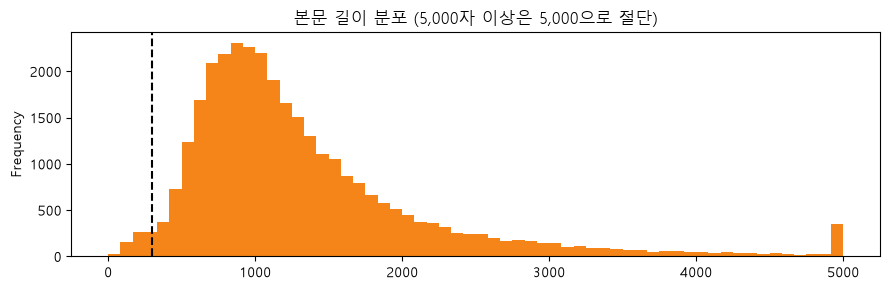

In [9]:
blen = bundle["body"].str.len()
print(blen.describe().round(0))
ax = blen.clip(upper=5000).plot.hist(bins=60, figsize=(9, 3), color="#F58518")
ax.axvline(lp.MIN_BODY_CHARS, color="k", ls="--"); ax.set_title("본문 길이 분포 (5,000자 이상은 5,000으로 절단)")
plt.tight_layout()
pd.cut(blen, [-1, 0, 100, 300, 500, 1000, 3000, 10000, 30000]).value_counts().sort_index()

In [10]:
bundle.loc[blen.between(1, 300), ["title", "body"]].sample(5, random_state=1)

,title,body
10237,APEC CEO 서밋서 발표하는 케빈 쉬 메보 CEO,케빈 쉬 메보(MEBO)그룹 CEO가 30일 경북 경주 예술의전당에서 열린 아시아태평양경제협력체(APEC) 정상회의 최고 경영자(CEO)...
12121,"마크로젠, 에프아이소프트와 건강 식품 추천 서비스 개발 협약",디지털 헬스케어 기업 마크로젠은 건강기능식품 추천 설루션 기업 에프아이소프트와 건강기능식품 추천 서비스 개발을 위한 업무 협약을 체결했다...
10243,"케빈 쉬 메보 CEO, APEC CEO 서밋서 발표",케빈 쉬 메보(MEBO)그룹 CEO가 30일 경북 경주 예술의전당에서 열린 아시아태평양경제협력체(APEC) 정상회의 최고 경영자(CEO)...
12104,"화순전남대병원, 차세대 병원 정보 시스템 ‘e-SMART’ 가동",화순전남대병원이 전남대병원 등과의 협진체제를 고도화하는 등의 차세대 병원 정보 시스템 가동에 들어갔습니다. 화순전남대병원은 환자의 안전과...
11444,"원주, ‘엔비디아 교육센터’ 설립 준비 착수","원주시가 '엔비디아 교육센터' 설립을 위한 준비 절차에 착수했습니다. 이에 따라, 올해 35억 원을 들여 원주 혁신도시 안에 센터가 들어..."


- 중앙값 약 1,100자, 75% 구간 1,600자 → **기사 1건 = 1~3개 청크**(500~800자 기준) 수준이다.
- 300자 미만은 대부분 **사진기사 캡션·속보 한 줄**이라 근거로 쓰기 어려워 제외한다(`MIN_BODY_CHARS = 300`).
- 1만 자 이상 장문 25건(인터뷰·특집)은 인덱서에서 문단 기준 분할이 필요하다.

### 6-1. 포털 보일러플레이트

In [11]:
body = bundle["body"]
pd.Series({p: int(body.str.contains(p, regex=True).sum()) for p in lp.BOILERPLATE_PATTERNS + [r"Copyrights?\s"]})

기사를\s*더\s*보고\s*싶다면\?                                          7203
기사\s*섹션\s*분류\s*안내                                             9960
이\s*기사를\s*추천합니다                                               6034
\(?[^()\s]*\s*재판매\s*및\s*DB\s*금지\)?                              15
Copyright\s*(?:ⓒ|\(c\))?.{0,40}?All\s*rights\s*reserved\.?      98
무단\s*전재[^.]{0,40}금지\.?                                          27
Copyrights?\s                                                  137
dtype: int64

In [12]:
bundle.loc[body.str.contains("기사 섹션 분류 안내"), "body"].str[-90:].head(3).tolist()

['in)을 형성하고 기업의 인프라 활성화와 기술경쟁력 향상을 위해 오는 9월 14일 송도에서 컨퍼런스를 개최할 예정이다. 기사 섹션 분류 안내 이 기사를 추천합니다',
 '오 의약품 원부자재 관련 재직자들의 교육훈련기회를 확대하기 위해 시행된다.   기사를 더 보고 싶다면?          기사 섹션 분류 안내 이 기사를 추천합니다',
 '재 연구와 생산, 판매를 병행할 예정이며, 이미 다수의 바이오 의약품 전문기업들과 업무협약을 맺어 4월부터 공급을 시작한다고 한다고 전했다. 기사 섹션 분류 안내']

- 약 1만 건 본문 끝에 `기사를 더 보고 싶다면? / 기사 섹션 분류 안내 / 이 기사를 추천합니다` 같은 **포털 UI 텍스트**가 섞여 있다.
- 그대로 임베딩하면 서로 다른 기사가 꼬리 텍스트 때문에 유사해지므로 적재 단계에서 제거한다(`clean_text`).

### 6-2. 제목 패턴 — 저정보 기사

In [13]:
prefix = bundle["title"].str.extract(r"^\s*[\[\(<]\s*([^\]\)>]{1,12})\s*[\]\)>]")[0]
prefix.value_counts().head(15)

0
ZD브리핑     150
특징주       112
단독         89
포토         64
마켓인        57
바이오게시판     54
르포         53
게시판        52
인터뷰        46
신년사        38
fn마켓워치     34
바이오스냅      33
미래의료       33
ZD 브리핑     33
현장         24
Name: count, dtype: int64

- `[포토]·[인사]·[부고]·[동정]`은 정보량이 낮아 제외한다.
- `[게시판]·[바이오게시판]`은 **투자 유치·제휴 단신 모음**이라 '바이오 투자' 근거가 많아 유지한다.

### 6-3. 중복

In [14]:
pd.Series({
    "URL(문서ID) 중복": int(bundle["url"].map(lp.make_doc_id).duplicated().sum()),
    "제목 중복": int(bundle["title"].duplicated().sum()),
    "본문 완전 중복": int(body[body != ""].duplicated().sum()),
})

URL(문서ID) 중복      2
제목 중복           814
본문 완전 중복        270
dtype: int64

In [15]:
d = bundle[body.duplicated(keep=False) & (body != "")].sort_values("body")
d[["title", "press", "published_at"]].head(6)

,title,press,published_at
29396,이동훈 사장 넥스트 신약은 중추신경계질환 치료제…게임체인저로 만들것,서울경제,2024-11-22T09:50:00
29397,"“SK바이오팜 세노바메이트, 2~3년 내 美 시장 1위로”",서울경제,2024-11-22T09:50:00
508,롯바 송도 1공장 첫삽..신동빈 韓 바이오 중심축 될 것,파이낸셜뉴스,2024-07-03T14:22:00
507,"롯데바이오, 송도캠퍼스 착공… CDMO 글로벌 톱10 진입",파이낸셜뉴스,2024-07-03T18:33:00
31786,엔비디아는 인프라 기업…전세계 AI 생산 공장 구축 주도,머니투데이,2025-05-20T04:05:00
31785,데이터센터 넘어 AI 생산 공장으로…젠슨 황 수조달러 시장 열린다,머니투데이,2025-05-19T17:10:00


- 제목만 같은 경우(약 800건)는 `[포토]` 연작·동일 행사 기사가 대부분이라 제목 기준 중복 제거는 위험하다.
- **본문 완전 중복**은 같은 매체가 제목만 바꿔 재송고한 경우 → 가장 이른 기사만 남긴다.
- **근사 중복**(통신사 전재 후 일부 수정)은 ② 인덱서 `dedup.py`에서 MinHash·임베딩 유사도로 처리한다.

## 7. 하위 주제 커버리지 (과제 키워드표 기준)

바이오 투자      3656
CDMO        2776
비대면 진료      2593
바이오시밀러      1121
의료 AI 규제     846
ADC          766
신약 기술수출      541
AI 신약개발      388
dtype: int64

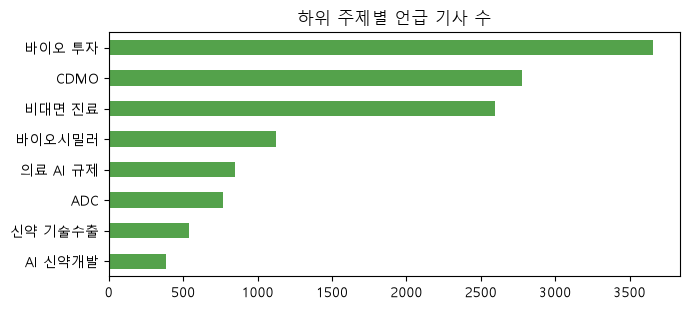

In [16]:
full = bundle["title"] + " " + body
topic_cnt = pd.Series({k: int(full.str.contains(p, regex=True).sum()) for k, p in lp.TOPIC_PATTERNS.items()}).sort_values()
ax = topic_cnt.plot.barh(figsize=(7, 3.2), color="#54A24B"); ax.set_title("하위 주제별 언급 기사 수")
plt.tight_layout(); topic_cnt.sort_values(ascending=False)

,ADC,CDMO,AI 신약개발,바이오 투자,신약 기술수출,의료 AI 규제,비대면 진료,바이오시밀러
published_at,,,,,,,,
2021,3,198,5,153,20,11,111,59
2022,32,632,38,709,113,179,841,143
2023,166,581,54,745,93,172,592,230
2024,204,499,70,767,127,100,376,259
2025,239,576,165,662,113,209,462,324
2026,122,290,56,620,75,175,211,106


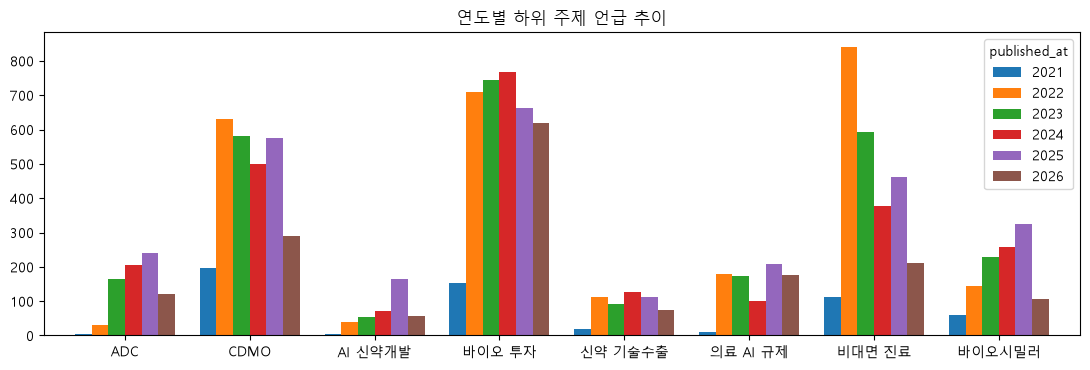

In [17]:
bt = b.assign(**{k: full.str.contains(p, regex=True) for k, p in lp.TOPIC_PATTERNS.items()})
yr = bt.groupby(bt["published_at"].dt.year)[list(lp.TOPIC_PATTERNS)].sum()
ax = yr.T.plot.bar(figsize=(11, 3.8), width=0.8); ax.set_title("연도별 하위 주제 언급 추이"); plt.xticks(rotation=0); plt.tight_layout()
yr

- 제공 데이터는 **'바이오 의약품 / 디지털 헬스케어' 두 키워드로만 수집**되어, 과제의 기술 하위어 중
  **ADC(약 760건)·AI 신약개발(약 390건)·신약 기술수출(약 540건)**은 상대적으로 얇다.
  → ① 수집기 크롤링 단계에서 이 키워드로 **뉴스를 보강**하고, 특허·투자보고서를 같은 하위 주제로 맞춰 수집한다.
- 연도별 추이로 주제의 부상·퇴조를 볼 수 있다. 같은 주제를 특허·보고서와 시간축으로 맞대는 것이 주제 B의 핵심 분석이다.

## 8. 뉴스 속 '전망' 서술 — 보고서와의 상충 비교 후보

In [18]:
outlook = full.str.contains(lp.OUTLOOK_PATTERN, regex=True)
print("전망성 서술 포함 비율:", round(outlook.mean(), 3))
sent = bundle.loc[outlook & full.str.contains("시장 규모|CAGR|연평균"), "body"]
sent.str.extract(r"([^.]{0,80}(?:시장 규모|CAGR|연평균)[^.]{0,80})")[0].dropna().head(6).tolist()

전망성 서술 포함 비율: 0.218


['일본 바이오 의약품 시장 규모가 95조원에 달하며 매년 커져가고 있지만, 해외 수입 의존도가 많게는 90% 가까이 되는 것으로 조사됐다',
 '국내 바이오 의약품 시장 규모가 연평균 16% 넘게 커진 것으로 나타났습니다',
 ' 국내 바이오 의약품 배지 시장 규모는 2027년, 8900억원까지 성장할 전망이지만 일부 연구용 액상 배지를 제외하고 대부분을 수입에 의존해왔는데 엔케이젠이 국산화에 성공한 것이',
 ' 롯데가 진출하는 항체 의약품 시장은 바이오 의약품 시장의 70% 이상을 차지하며, 연평균 성장률 10%의 안정적인 성장이 전망되는 분야다',
 ' 연평균 성장률 10%의 안정적인 성장이 전망되는 분야로 대표적인 항체 의약품 CDMO 기업들에서 높은 수준의 가동률을 보이고 있지만 생산 시설 부족으',
 ' 연평균 성장률 10%의 안정적인 성장이 전망되는 분야로 대표적인 항체 의약품 CDMO 기업들에서 높은 수준의 가동률을 보이고 있지만 생산 시설 부족으']

- 뉴스의 약 1/5이 시장 규모·성장률 등 **전망 수치**를 인용한다. 같은 시장에 대해 출처마다 수치가 달라
  **'뉴스가 인용한 전망 vs 투자보고서 원문 전망'의 상충**을 탐지하기 좋은 지점이다.
- `is_outlook` 플래그를 메타데이터로 저장해 검색 시 전망 근거를 따로 모을 수 있게 한다.

## 9. 선별 결과 (load_provided 파이프라인)

In [19]:
merged = lp.normalize(lp.merge_sources(list(raw.values())))
kept, rejected = lp.select(merged)
funnel = pd.Series({"원본 행(3파일)": sum(len(v) for v in raw.values()), "고유 문서": len(merged), "선별 후": len(kept)})
display(funnel)
rejected["drop_reason"].value_counts()

원본 행(3파일)    65025
고유 문서        32452
선별 후         31192
dtype: int64

drop_reason
short_body          544
off_topic           414
exact_dup_body      118
noise_title         101
non_news_section     66
empty_body           17
Name: count, dtype: int64

In [20]:
for r, g in rejected.groupby("drop_reason"):
    print(f"[{r}]", " | ".join(g["title"].sample(min(3, len(g)), random_state=0)))

[empty_body] 디지털 헬스케어 법안 폐기 촉구 시민단체 기자회견 | 인천시의회, 디지털 헬스케어 산업 지원 법적 기반 마련 | [속보]삼성전자, 美 디지털 헬스케어 회사 '젤스' 인수
[exact_dup_body] 디지털 헬스케어 240억 원 공사 중단...“예산 부족” | 디지털 헬스케어 240억 원 공사 중단...“예산 부족” | 춘천·원주 바이오산업, “전략 거점 육성”
[noise_title] [포토]'면역조절 기반 신개념 범용성 폐렴 치료제 개발'을 주제로 강연하는 이도영 본부장 | [포토] 오바이헬스 기기 관람하는 대통령 | [포토] 바디프랜드, CES 2022서 첨단 안마의자 공개...헬스케어 미래 제시
[non_news_section] 민간기업 글로벌 진출 교두보 된 '코리아컵'...민간기술 해외 판로 지원 | 휴온스그룹, 제천국제음악영화제 5000만원 쾌척 | 은퇴 선수 멘탈케어까지 책임진다...야구 OB 모임 일구회, 왓슨앤컴퍼니와 MOU 체결
[off_topic] 티웨이항공, 올해 1분기 화물 물동량 9000t... 전년比 78% 증가 전망 | 정부, 납사 수급 통제 나선다...수출 제한·매점매석 금지 추진 | [경주APEC]이규호 코오롱 부회장, 정책 권고안 전달...기업 목소리 반영되도록
[short_body] 이젠 운동도 스마트하게 | 제약바이오헬스케어연합회 출범... 6개 단체 협력 | 명절 연휴 피로, 헬스케어 가전으로 해소


In [21]:
year = kept["published_at"].dt.year
pd.DataFrame({
    "기사 수": kept.groupby(year).size(),
    "전망 서술 비율": kept.groupby(year)["is_outlook"].mean().round(2),
    "하위 주제 태깅 비율": kept.groupby(year)["topics"].apply(lambda s: (s != "").mean()).round(2),
    "평균 길이": kept.groupby(year)["char_len"].mean().round(0),
})

,기사 수,전망 서술 비율,하위 주제 태깅 비율,평균 길이
published_at,,,,
2021,1111,0.32,0.40,1311.0
2022,5729,0.22,0.38,1390.0
2023,6338,0.22,0.33,1377.0
2024,5471,0.22,0.34,1348.0
2025,7225,0.22,0.28,1347.0
2026,5318,0.19,0.25,1332.0


## 10. 결론 — 다음 단계 설계에 반영할 사항

| 발견 | 반영 위치 | 조치 |
|---|---|---|
| 묶음 파일 = 키워드 파일 합집합, URL 형식 다양 | ① `load_provided.py` | oid/aid 기반 `doc_id`로 병합, 수집키워드 합집합 보존 |
| 포털 UI 텍스트가 본문 꼬리에 혼입 | ① `clean_text` | 보일러플레이트 제거 후 저장 |
| 300자 미만 사진기사, [포토]/[인사] 등 | ① `select` | 제외 사유와 함께 `rejected_docs`에 기록 |
| 본문 완전 중복 / 근사 중복 | ① / ② `dedup.py` | 완전 중복은 적재 시, 근사 중복은 인덱싱 시 제거 |
| 기사 길이 중앙값 약 1.1천 자 | ② `chunk.py` | 뉴스는 문단 단위 500~800자 청크, 제목을 청크 앞에 부착 |
| 디지털 헬스케어 : 바이오 의약품 ≈ 4 : 1 | ③·④ 검색 | `collect_keywords`, `topics` 메타데이터 필터 |
| ADC·AI 신약개발·기술수출 문서 부족 | ① 크롤러 | 하위 키워드 뉴스 + 특허 + 투자보고서 보강 |
| 뉴스의 약 22%가 전망 수치 인용 | ③·④ 체인 | `is_outlook`, `evidence_role`로 출처·시간축별 근거를 나눠 답변 구성 |